# Task 25 - Linear Regression with Advanced Feature Selection, Interaction Terms and Cross-Validation

**Goal:** train a Linear Regression model, apply advanced feature selection, test interaction terms, and make sure the result is robust with cross-validation.

**Data mapping (please read):** there is no `yearly amount spent` column (no customers or transactions). The nearest real quantity is **estimated sales revenue per product = `price` x `units_sold`**, which is a snapshot, not a yearly figure, and `units_sold` is a bucketed estimate. The regression predicts **`log_revenue = log1p(price x units_sold)`**. Rename `TARGET_NAME` if you later get a true spend column.

**Leakage control:** revenue is built from `units_sold`, and `rating_count` is almost proportional to it, so both are excluded, together with every column derived from them (engagement, channel, lifecycle, target-encoded, shrunk-rating columns). `price` and its derivatives *are* allowed (they are known product attributes) but they make part of the fit mechanical, so the notebook also reports a **price-only baseline**; judge the model by its gain over that baseline. Set `INCLUDE_PRICE_FEATURES = False` to drop price columns.

**Selection techniques compared (always fitted inside each CV fold, so there is no selection leakage):** F-test, mutual information, Lasso-based, RFE with linear regression, forward sequential selection (on a pre-filtered pool), and no selection; sizes k = 5-30.
**Interactions:** pairwise products and squares of the strongest features, screened with CV gain and FDR-corrected p-values, then added greedily only if they improve CV error.
**Robustness:** repeated k-fold, selection-frequency across folds, bootstrap coefficient sign stability.

**Input:** newest file in `data/processed/`. **Outputs:** `data/processed/womens_clothing_regression_dataset.csv` (used by Tasks 26-27), `reports/task_25_feature_selection_results.csv`, `reports/task_25_selected_features.csv`, `reports/task_25_interaction_terms.csv`, `reports/task_25_model_comparison.csv`, `reports/task_25_analysis_status.csv`

In [1]:
import re, warnings
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

def find_project_root():
    """Walk up from the notebook folder until a folder containing data/processed is found."""
    start = Path.cwd().resolve()
    for cand in [start, *start.parents]:
        if (cand / "data" / "processed").exists():
            return cand
    return start.parent

ROOT = find_project_root()
PROC, REPORTS = ROOT / "data" / "processed", ROOT / "reports"
RAW = ROOT / "data" / "raw" / "womens_clothing.csv"
PROC.mkdir(parents=True, exist_ok=True); REPORTS.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

def _norm(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())

def pick(df, *candidates, required=True):
    """Return the real column name matching any candidate (ignores case, spaces, underscores)."""
    lookup = {_norm(c): c for c in df.columns}
    for cand in candidates:
        if _norm(cand) in lookup:
            return lookup[_norm(cand)]
    if required:
        raise KeyError(f"None of {candidates} found. Columns: {list(df.columns)}")
    return None

def load_first(*paths):
    """Load the first existing CSV, so each task builds on the newest previous output."""
    for p in paths:
        if Path(p).exists():
            d = pd.read_csv(p)
            d = d.loc[:, ~d.columns.str.startswith("Unnamed")]
            print(f"Loaded: {Path(p).name}  shape={d.shape}")
            return d, Path(p)
    raise FileNotFoundError("None of these files exist: " + ", ".join(str(p) for p in paths))

def add_from_raw(df, *names):
    """Borrow columns missing from df (e.g. title, tags) from data/raw, matched on product_id."""
    missing = [n for n in names if pick(df, n, required=False) is None]
    if not missing:
        return df
    raw = pd.read_csv(RAW); raw = raw.loc[:, ~raw.columns.str.startswith("Unnamed")]
    kd, kr = pick(df, "product_id", required=False), pick(raw, "product_id", required=False)
    if kd is None or kr is None:
        raise KeyError(f"Need product_id in both files to borrow {missing} from raw")
    got = [pick(raw, n) for n in missing if pick(raw, n, required=False)]
    if not got:
        raise KeyError(f"{missing} not found in raw file either")
    add = raw.drop_duplicates(kr)[[kr] + got].rename(columns={kr: kd})
    out = df.merge(add, on=kd, how="left")
    print("Borrowed from raw:", got)
    return out

# Newest cumulative dataset first; each task reads the newest file produced BEFORE it.
CHAIN = ["womens_clothing_high_cardinality_encoded.csv", "womens_clothing_engagement_features.csv",
         "womens_clothing_sentiment_features.csv", "womens_clothing_age_segmented.csv",
         "womens_clothing_review_text_features.csv", "womens_clothing_market_basket_features.csv",
         "womens_clothing_product_text_features.csv", "womens_clothing_product_tag_features.csv",
         "womens_clothing_product_segmented.csv", "womens_clothing_final.csv"]

# Tasks 19-21 outputs sit in front of the older chain.
LATE = ["womens_clothing_lifecycle_features.csv", "womens_clothing_tfidf_features.csv", "womens_clothing_channel_interaction_features.csv"]
FULL = LATE + CHAIN

# Tasks 22-24 outputs sit in front of everything.
LATE2 = ["womens_clothing_rating_sentiment_encoded.csv", "womens_clothing_pca_features.csv"]
ALL = LATE2 + FULL

REG_DATASET = "womens_clothing_regression_dataset.csv"      # written by Task 25, read by Tasks 26-27

import itertools, time
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.feature_selection import SelectKBest, f_regression, mutual_info_regression, SelectFromModel, RFE, SequentialFeatureSelector
from sklearn.model_selection import KFold, RepeatedKFold, cross_validate
sns.set_theme(style="whitegrid"); pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42
TARGET_NAME = "log_revenue"
INCLUDE_PRICE_FEATURES = True
K_GRID = [5, 10, 15, 20, 30]
SFS_POOL, SFS_K_GRID = 30, [5, 10, 15]          # forward selection is expensive: pre-filter to 30 features, try k <= 15
MAX_INTERACTIONS, INTERACTION_BASE = 5, 8       # greedy interactions among the 8 strongest features
CORR_LIMIT = 0.95

Project root: D:\OneDrive\Desktop\Brainybeams\Womens_Clothing_ML_Project


## 1. Load data and build the target

Loaded: womens_clothing_rating_sentiment_encoded.csv  shape=(1539, 155)
Products: 1,539 | revenue: median 7,000, max 231,717 | target skew raw 1.8 -> log -0.20


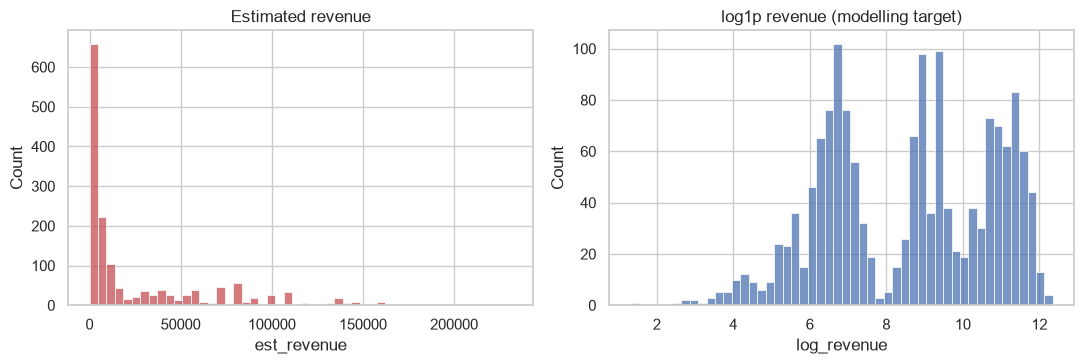

In [2]:
df, src = load_first(*[PROC / n for n in ALL])
price_col = pick(df, "price"); units_col = pick(df, "units_sold"); id_col = pick(df, "product_id", required=False)
assert df[price_col].min() > 0, "price looks scaled - use an un-scaled file"
df["est_revenue"] = df[price_col] * df[units_col]
y = np.log1p(df["est_revenue"]); y.name = TARGET_NAME
print(f"Products: {len(df):,} | revenue: median {df['est_revenue'].median():,.0f}, max {df['est_revenue'].max():,.0f} | target skew raw {df['est_revenue'].skew():.1f} -> log {y.skew():.2f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8)); sns.histplot(df["est_revenue"], bins=50, ax=ax[0], color="#c44e52"); ax[0].set_title("Estimated revenue")
sns.histplot(y, bins=50, ax=ax[1], color="#4c72b0"); ax[1].set_title("log1p revenue (modelling target)"); plt.tight_layout(); plt.show()

## 2. Candidate feature pool (leakage-safe) and transformations

In [3]:
excl_exact = {units_col, "est_revenue", "rating_count", "rating_one_count", "rating_two_count", "rating_three_count", "rating_four_count", "rating_five_count", "inventory_total"}
excl_prefix = ("eng_", "engagement", "is_highly", "ch_", "lc_", "lifecycle", "te_", "rating_sentiment", "rs_", "rating_confident", "ttl_rating_reliable", "unnamed")
if not INCLUDE_PRICE_FEATURES:
    excl_prefix += ("price_tier", "discount")
    excl_exact |= {price_col, "retail_price"}
num = df.select_dtypes(include=["number", "bool"]).copy(); num = num.astype({c: int for c in num.columns if num[c].dtype == bool})
drop = [c for c in num.columns if c in excl_exact or c.lower().startswith(excl_prefix) or (id_col and c == id_col) or re.search(r"(^|_)id$", c.lower())]
if not INCLUDE_PRICE_FEATURES: drop += [c for c in num.columns if c.lower().startswith("price") and c not in drop]
X0 = num.drop(columns=list(dict.fromkeys(drop)))
X0 = X0.loc[:, X0.notna().any() & (X0.nunique() > 1)]; X0 = X0.fillna(X0.median())
print(f"{X0.shape[1]} numeric candidates | excluded: {len(set(drop))}"); print("Excluded:", sorted(set(drop)))

# log-transform strongly right-skewed non-negative columns so a linear model suits them
tf = {}; cols = {}
for c in X0.columns:
    s = X0[c]
    if s.min() >= 0 and s.nunique() > 10 and s.skew() > 2: cols[f"log1p_{c}"] = np.log1p(s); tf[c] = "log1p"
    else: cols[c] = s
X1 = pd.DataFrame(cols, index=df.index)
print("Log-transformed:", list(tf))

# drop near-duplicate columns (|r| > CORR_LIMIT), keeping the one most correlated with the target
cor = X1.corr().abs(); tcor = X1.apply(lambda s: abs(np.corrcoef(s, y)[0, 1]) if s.std() > 0 else 0)
keep = []
for c in sorted(X1.columns, key=lambda c: -tcor[c]):
    if all(cor.loc[c, k] <= CORR_LIMIT for k in keep): keep.append(c)
dropped_corr = sorted(set(X1.columns) - set(keep)); X = X1[keep]
print(f"Correlation filter removed {len(dropped_corr)} near-duplicates -> pool of {X.shape[1]} features")
tcor.loc[keep].sort_values(ascending=False).head(10).round(3)

95 numeric candidates | excluded: 32
Excluded: ['eng_feedback_received', 'eng_review_effort', 'engagement_cluster_id', 'engagement_index', 'engagement_score', 'engagement_stat_high', 'est_revenue', 'fe_product_variation_size_id', 'inventory_total', 'is_highly_engaged', 'rating_confident', 'rating_count', 'rating_five_count', 'rating_four_count', 'rating_one_count', 'rating_sentiment_neg_threshold', 'rating_sentiment_negative', 'rating_sentiment_neutral', 'rating_sentiment_ord', 'rating_sentiment_pos_threshold', 'rating_sentiment_pos_vs_rest', 'rating_sentiment_positive', 'rating_sentiment_target_enc_oof', 'rating_three_count', 'rating_two_count', 'rs_rating_shrunk', 'rs_vote_net_index', 'rs_vote_pos_share', 'te_product_color', 'te_product_variation_size_id', 'te_shipping_option_name', 'units_sold']
Log-transformed: []
Correlation filter removed 7 near-duplicates -> pool of 88 features


merchant_rating_count              0.319
product_variation_inventory        0.294
price                              0.252
pca_cat_5                          0.245
shipping_option_price              0.235
merchant_rating                    0.212
svd_product_variation_size_id_2    0.203
svd_product_variation_size_id_1    0.186
pca_cat_21                         0.172
svd_product_variation_size_id_3    0.168
dtype: float64

## 3. Baselines

In [4]:
kf = KFold(5, shuffle=True, random_state=RANDOM_STATE)
def cv_scores(pipe, A, repeats=1):
    cv = RepeatedKFold(n_splits=5, n_repeats=repeats, random_state=RANDOM_STATE) if repeats > 1 else kf
    r = cross_validate(pipe, A, y, cv=cv, scoring={"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}, return_train_score=True, n_jobs=-1)
    return {"rmse": -r["test_rmse"].mean(), "rmse_sd": r["test_rmse"].std(), "mae": -r["test_mae"].mean(), "r2": r["test_r2"].mean(), "r2_sd": r["test_r2"].std(), "train_r2": r["train_r2"].mean()}
price_feat = [c for c in X.columns if "price" in c.lower() and "tier" not in c.lower()][:1] or [X.columns[0]]
base_all = cv_scores(make_pipeline(StandardScaler(), LinearRegression()), X)
base_price = cv_scores(make_pipeline(StandardScaler(), LinearRegression()), X[price_feat])
print("Price-only baseline:", price_feat, {k: round(v, 4) for k, v in base_price.items()})
print("All features (no selection):", {k: round(v, 4) for k, v in base_all.items()})

Price-only baseline: ['price'] {'rmse': np.float64(2.1176), 'rmse_sd': np.float64(0.0497), 'mae': np.float64(1.8435), 'r2': np.float64(0.0579), 'r2_sd': np.float64(0.0181), 'train_r2': np.float64(0.0635)}
All features (no selection): {'rmse': np.float64(1.8329), 'rmse_sd': np.float64(0.0459), 'mae': np.float64(1.4944), 'r2': np.float64(0.2937), 'r2_sd': np.float64(0.0312), 'train_r2': np.float64(0.3937)}


## 4. Feature selection techniques (nested inside CV)

Each configuration is a pipeline *scaler -> selector -> linear regression*, so features are re-selected inside every training fold. Forward selection is run on the 30 features with the strongest F-scores to keep it tractable.

In [5]:
def mi_fn(A, b): return mutual_info_regression(A, b, random_state=RANDOM_STATE)
def make_selector(method, k):
    if method == "f_test": return SelectKBest(f_regression, k=k)
    if method == "mutual_info": return SelectKBest(mi_fn, k=k)
    if method == "lasso": return SelectFromModel(LassoCV(cv=3, random_state=RANDOM_STATE, max_iter=5000), max_features=k, threshold=-np.inf)
    if method == "rfe": return RFE(LinearRegression(), n_features_to_select=k, step=0.2)
    if method == "forward_sfs":
        return Pipeline([("pre", SelectKBest(f_regression, k=min(SFS_POOL, X.shape[1]))),
                         ("sfs", SequentialFeatureSelector(LinearRegression(), n_features_to_select=k, direction="forward", scoring="neg_root_mean_squared_error", cv=3, n_jobs=-1))])
def make_pipe(method, k): return Pipeline([("scale", StandardScaler()), ("sel", make_selector(method, k)), ("lr", LinearRegression())])

rows = []
t_all = time.time()
for method in ["f_test", "mutual_info", "lasso", "rfe", "forward_sfs"]:
    for k in (SFS_K_GRID if method == "forward_sfs" else K_GRID):
        if k >= X.shape[1]: continue
        t0 = time.time(); r = cv_scores(make_pipe(method, k), X)
        rows.append({"method": method, "k": k, **r, "seconds": time.time() - t0})
rows.append({"method": "none (all features)", "k": X.shape[1], **base_all, "seconds": 0})
sel_res = pd.DataFrame(rows).sort_values("rmse").reset_index(drop=True)
print(f"Selection grid finished in {time.time() - t_all:.0f}s"); sel_res.round(4)

Selection grid finished in 37s


,method,k,rmse,rmse_sd,mae,r2,r2_sd,train_r2,seconds
0,none (all features),88,1.8329,0.0459,1.4944,0.2937,0.0312,0.3937,0.0000
1,f_test,20,1.8423,0.0318,1.5192,0.2858,0.0377,0.3110,0.0830
2,mutual_info,30,1.8448,0.0337,1.5252,0.2841,0.0348,0.3168,1.1603
3,f_test,30,1.8483,0.0354,1.5220,0.2812,0.0392,0.3313,0.0848
4,rfe,30,1.8555,0.0388,1.5143,0.2760,0.0317,0.3518,0.0990
5,lasso,30,1.8614,0.0393,1.5276,0.2717,0.0238,0.3599,0.3871
6,f_test,15,1.8625,0.0292,1.5459,0.2702,0.0354,0.2953,0.0926
7,lasso,15,1.8637,0.0403,1.5342,0.2693,0.0378,0.3182,0.5224
8,forward_sfs,15,1.8662,0.0408,1.5352,0.2669,0.0452,0.3146,12.4783
9,lasso,10,1.8687,0.0377,1.5501,0.2652,0.0406,0.2959,0.4371


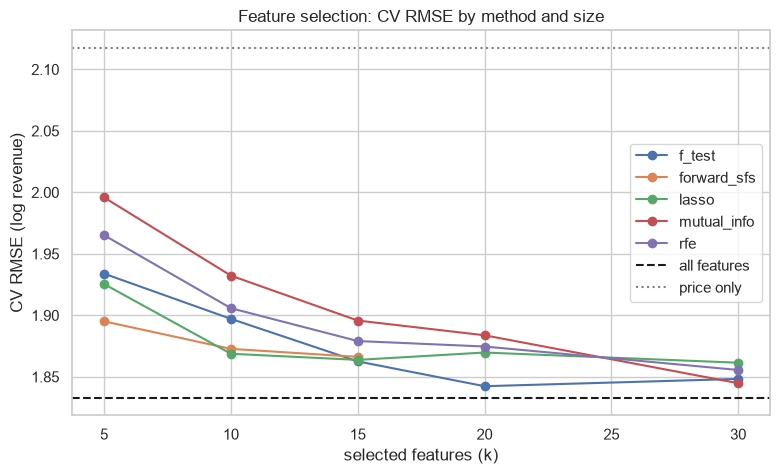

In [6]:
plt.figure(figsize=(9, 5))
for m, g in sel_res[sel_res["method"] != "none (all features)"].groupby("method"): plt.plot(g.sort_values("k")["k"], g.sort_values("k")["rmse"], marker="o", label=m)
plt.axhline(base_all["rmse"], color="k", ls="--", label="all features"); plt.axhline(base_price["rmse"], color="grey", ls=":", label="price only")
plt.xlabel("selected features (k)"); plt.ylabel("CV RMSE (log revenue)"); plt.legend(); plt.title("Feature selection: CV RMSE by method and size"); plt.show()

In [7]:
cand = sel_res[sel_res["method"] != "none (all features)"]
best = cand.iloc[0]; se = best["rmse_sd"] / np.sqrt(5)
choice = cand[cand["rmse"] <= best["rmse"] + se].sort_values(["k", "rmse"]).iloc[0]            # simplest within 1 SE
print(f"Best: {best['method']} k={int(best['k'])} (RMSE {best['rmse']:.4f}) | chosen (simplest within 1 SE): {choice['method']} k={int(choice['k'])} (RMSE {choice['rmse']:.4f})")

def chain_support(pipe, n):
    """Boolean mask over the original columns for a fitted scaler -> (selector | pre+sfs) pipeline."""
    mask = np.ones(n, bool); sel = pipe.named_steps["sel"]
    steps = [s for _, s in sel.steps] if isinstance(sel, Pipeline) else [sel]
    for s in steps:
        sub = s.get_support(); m = np.zeros(n, bool); m[np.where(mask)[0][sub]] = True; mask = m
    return mask
mth, kk = choice["method"], int(choice["k"])
full_fit = make_pipe(mth, kk).fit(X, y); selected = list(X.columns[chain_support(full_fit, X.shape[1])])
# selection frequency across repeated folds = stability of the chosen features
freq = pd.Series(0.0, index=X.columns); nsp = 0
for tr, _ in RepeatedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE).split(X):
    freq[X.columns[chain_support(make_pipe(mth, kk).fit(X.iloc[tr], y.iloc[tr]), X.shape[1])]] += 1; nsp += 1
freq /= nsp
print("Selected:", selected); freq.loc[selected].sort_values(ascending=False).round(2).to_frame("selection_frequency")

Best: f_test k=20 (RMSE 1.8423) | chosen (simplest within 1 SE): f_test k=20 (RMSE 1.8423)
Selected: ['merchant_rating_count', 'product_variation_inventory', 'price', 'pca_cat_5', 'shipping_option_price', 'merchant_rating', 'svd_product_variation_size_id_2', 'svd_product_variation_size_id_1', 'pca_cat_21', 'svd_product_variation_size_id_3', 'txt_word_count', 'svd_product_variation_size_id_4', 'txt_char_count', 'txt_title_word_count', 'pca_cat_4', 'merchant_has_profile_picture', 'badge_product_quality', 'pca_cat_3', 'pca_cat_14', 'pca_cat_17']


,selection_frequency
merchant_rating_count,1.00
product_variation_inventory,1.00
price,1.00
pca_cat_5,1.00
shipping_option_price,1.00
merchant_rating,1.00
svd_product_variation_size_id_2,1.00
svd_product_variation_size_id_1,1.00
pca_cat_21,1.00
svd_product_variation_size_id_3,1.00


## 5. Interaction terms

Candidates: pairwise products and squares of the `INTERACTION_BASE` strongest selected features (standardised first, so products are comparable). Each is screened by its p-value (Benjamini-Hochberg FDR) and by the CV RMSE gain when added to the base model; interactions are then added greedily while CV error keeps improving.

In [8]:
Z = pd.DataFrame(StandardScaler().fit_transform(X[selected]), index=X.index, columns=selected)
ols = sm.OLS(y, sm.add_constant(Z)).fit()
strong = list(ols.params.drop("const").abs().sort_values(ascending=False).index[:INTERACTION_BASE])
cand_terms = {f"ix__{a}__{b}": Z[a] * Z[b] for a, b in itertools.combinations(strong, 2)}
cand_terms.update({f"sq__{a}": Z[a] ** 2 for a in strong})
cvr = RepeatedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)
def cv_rmse(A): return -cross_validate(LinearRegression(), A, y, cv=cvr, scoring="neg_root_mean_squared_error", n_jobs=-1)["test_score"].mean()
base_rmse = cv_rmse(Z); rows = []
for name, col in cand_terms.items():
    m = sm.OLS(y, sm.add_constant(pd.concat([Z, col.rename(name)], axis=1))).fit()
    rows.append({"term": name, "coef_std": m.params[name], "p_value": m.pvalues[name], "cv_rmse_with_term": cv_rmse(pd.concat([Z, col.rename(name)], axis=1))})
ix = pd.DataFrame(rows); ix["cv_rmse_gain"] = base_rmse - ix["cv_rmse_with_term"]
ix["q_value_fdr"] = multipletests(ix["p_value"], method="fdr_bh")[1]
ix = ix.sort_values("cv_rmse_gain", ascending=False).reset_index(drop=True); print(f"Base CV RMSE: {base_rmse:.4f}"); ix.head(12).round(5)

Base CV RMSE: 1.8401


,term,coef_std,p_value,cv_rmse_with_term,cv_rmse_gain,q_value_fdr
0,sq__price,-0.26723,0.00000,1.81080,0.02930,0.00000
1,sq__merchant_rating_count,-0.40303,0.00000,1.81714,0.02296,0.00000
2,sq__txt_word_count,0.07611,0.00360,1.83539,0.00472,0.02595
3,ix__price__txt_char_count,-0.17103,0.00129,1.83567,0.00443,0.01545
4,ix__txt_word_count__txt_char_count,0.07596,0.00737,1.83611,0.00399,0.03678
5,sq__txt_char_count,0.07697,0.00817,1.83650,0.00360,0.03678
6,ix__txt_char_count__product_variation_inventory,-0.14225,0.00269,1.83690,0.00321,0.02425
7,ix__product_variation_inventory__pca_cat_21,0.12361,0.01269,1.83694,0.00316,0.05076
8,ix__txt_word_count__pca_cat_21,0.10790,0.02102,1.83796,0.00214,0.06879
9,ix__txt_char_count__pca_cat_21,0.10780,0.02426,1.83804,0.00206,0.07278


In [9]:
# Greedy forward addition: accept a term only if it lowers repeated-CV RMSE by at least MIN_GAIN
MIN_GAIN = 0.002; chosen_ix, cur, cur_rmse = [], Z.copy(), base_rmse
for _ in range(MAX_INTERACTIONS):
    trial = {n: cv_rmse(pd.concat([cur, cand_terms[n].rename(n)], axis=1)) for n in cand_terms if n not in chosen_ix}
    if not trial: break
    n_best = min(trial, key=trial.get)
    if cur_rmse - trial[n_best] < MIN_GAIN: break
    chosen_ix.append(n_best); cur = pd.concat([cur, cand_terms[n_best].rename(n_best)], axis=1); cur_rmse = trial[n_best]
    print(f"added {n_best}: CV RMSE {cur_rmse:.4f}")
print("Interactions kept:", chosen_ix or "none (no interaction improved CV error)")
ix["kept"] = ix["term"].isin(chosen_ix)

added sq__price: CV RMSE 1.8108
added sq__merchant_rating_count: CV RMSE 1.7870
added sq__txt_word_count: CV RMSE 1.7828
added ix__price__txt_char_count: CV RMSE 1.7797
added ix__product_variation_inventory__pca_cat_21: CV RMSE 1.7770
Interactions kept: ['sq__price', 'sq__merchant_rating_count', 'sq__txt_word_count', 'ix__price__txt_char_count', 'ix__product_variation_inventory__pca_cat_21']


## 6. Final comparison with repeated cross-validation (5 x 3 folds)

In [10]:
A_sel = X[selected]; A_ix = pd.concat([X[selected], pd.DataFrame({n: cand_terms[n].values for n in chosen_ix}, index=X.index)], axis=1) if chosen_ix else A_sel
lr = make_pipeline(StandardScaler(), LinearRegression())
comp = pd.DataFrame({"price-only baseline": cv_scores(lr, X[price_feat], repeats=3), "all features": cv_scores(lr, X, repeats=3),
                     f"selected ({mth}, k={kk})": cv_scores(lr, A_sel, repeats=3), "selected + interactions": cv_scores(lr, A_ix, repeats=3)}).T
comp["n_features"] = [len(price_feat), X.shape[1], len(selected), A_ix.shape[1]]
comp["overfit_gap_r2"] = comp["train_r2"] - comp["r2"]; comp.round(4)

,rmse,rmse_sd,mae,r2,r2_sd,train_r2,n_features,overfit_gap_r2
price-only baseline,2.1184,0.0402,1.8439,0.0567,0.0250,0.0635,1,0.0068
all features,1.8240,0.0596,1.4844,0.3005,0.0368,0.3932,88,0.0928
"selected (f_test, k=20)",1.8398,0.0486,1.5151,0.2880,0.0383,0.3121,20,0.0241
selected + interactions,1.7786,0.0387,1.4623,0.3346,0.0304,0.3634,25,0.0287


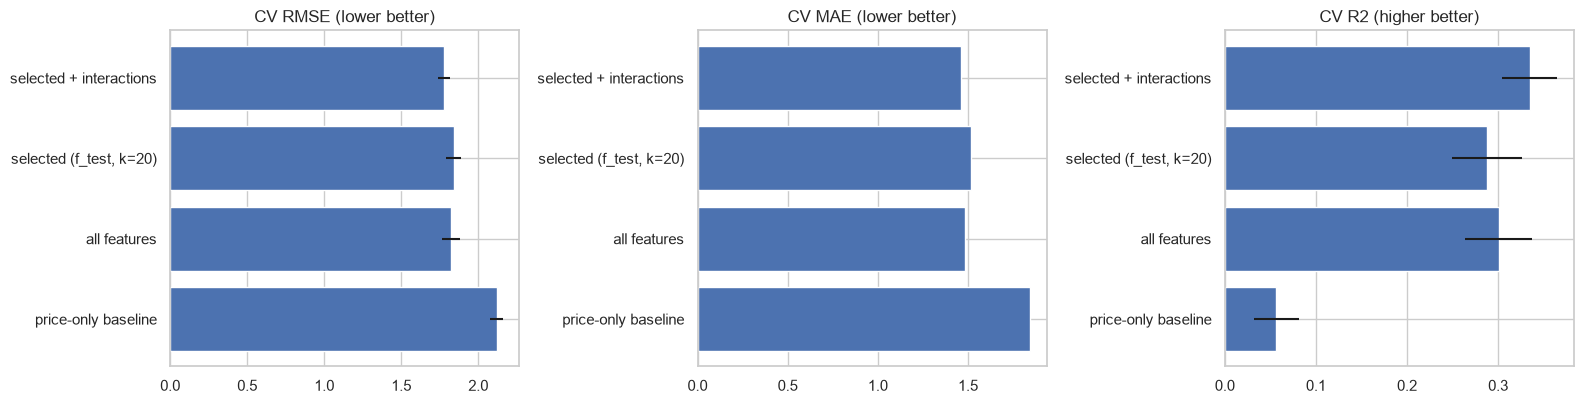

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for a, m, t in zip(ax, ["rmse", "mae", "r2"], ["CV RMSE (lower better)", "CV MAE (lower better)", "CV R2 (higher better)"]):
    a.barh(comp.index, comp[m], xerr=comp["rmse_sd"] if m == "rmse" else (comp["r2_sd"] if m == "r2" else None), color="#4c72b0"); a.set_title(t)
plt.tight_layout(); plt.show()

## 7. Robustness: coefficient stability (bootstrap) and final coefficients

In [12]:
Zf = pd.DataFrame(StandardScaler().fit_transform(A_ix), index=A_ix.index, columns=A_ix.columns)
final = sm.OLS(y, sm.add_constant(Zf)).fit()
rng = np.random.default_rng(RANDOM_STATE); signs = []
for _ in range(300):
    b = rng.integers(0, len(Zf), len(Zf)); signs.append(np.sign(sm.OLS(y.values[b], sm.add_constant(Zf.iloc[b])).fit().params.drop("const").values))
sign_stab = pd.Series(np.abs(np.mean(signs, axis=0)) / 2 + 0.5, index=Zf.columns)           # share of bootstraps agreeing with the majority sign
coef = pd.DataFrame({"coef_standardised": final.params.drop("const"), "std_err": final.bse.drop("const"), "t": final.tvalues.drop("const"), "p_value": final.pvalues.drop("const"),
                     "ci_low": final.conf_int().drop("const")[0], "ci_high": final.conf_int().drop("const")[1], "bootstrap_sign_stability": sign_stab,
                     "selection_frequency": freq.reindex(Zf.columns)})
coef["type"] = np.where(coef.index.str.startswith(("ix__", "sq__")), "interaction", "original"); coef = coef.sort_values("t", key=abs, ascending=False)
print(f"Final model: R2 {final.rsquared:.3f} (in-sample), adj R2 {final.rsquared_adj:.3f}, F-test p {final.f_pvalue:.2e}"); coef.round(4).head(15)

Final model: R2 0.361 (in-sample), adj R2 0.350, F-test p 6.29e-128


,coef_standardised,std_err,t,p_value,ci_low,ci_high,bootstrap_sign_stability,selection_frequency,type
merchant_rating_count,1.0254,0.0904,11.3451,0.0000,0.8481,1.2026,1.0,1.0000,original
sq__price,-0.3559,0.0505,-7.0417,0.0000,-0.4550,-0.2567,1.0,NaN,interaction
sq__merchant_rating_count,-0.5786,0.0862,-6.7090,0.0000,-0.7477,-0.4094,1.0,NaN,interaction
price,0.5354,0.0949,5.6431,0.0000,0.3493,0.7216,1.0,1.0000,original
pca_cat_21,-0.2409,0.0469,-5.1390,0.0000,-0.3329,-0.1490,1.0,1.0000,original
product_variation_inventory,0.2235,0.0533,4.1963,0.0000,0.1190,0.3280,1.0,1.0000,original
pca_cat_14,-0.1795,0.0503,-3.5703,0.0004,-0.2782,-0.0809,1.0,1.0000,original
pca_cat_3,-0.1847,0.0521,-3.5411,0.0004,-0.2869,-0.0824,1.0,0.9333,original
pca_cat_17,0.1728,0.0511,3.3786,0.0007,0.0725,0.2731,1.0,0.6667,original
badge_product_quality,0.1550,0.0464,3.3389,0.0009,0.0639,0.2460,1.0,1.0000,original


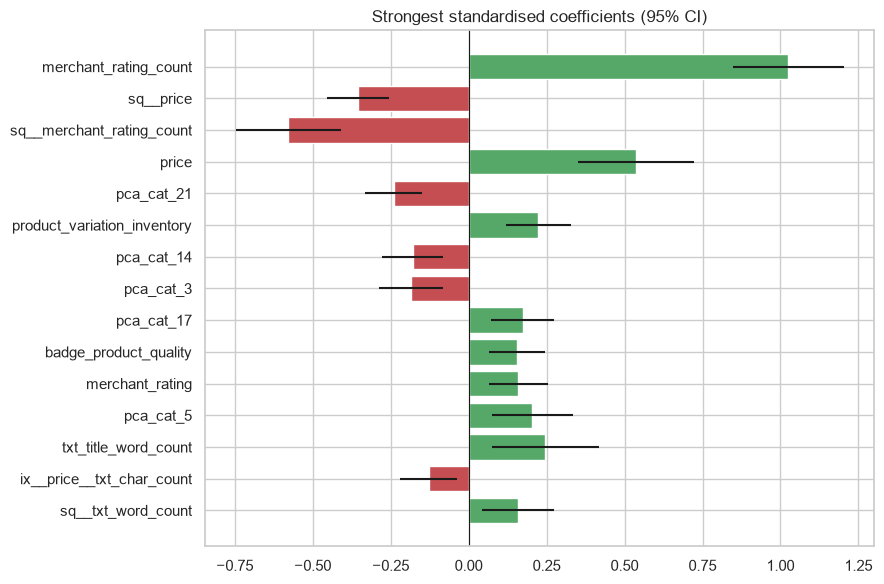

In [13]:
t = coef.head(15).iloc[::-1]
plt.figure(figsize=(9, 6)); plt.barh(t.index, t["coef_standardised"], xerr=1.96 * t["std_err"], color=np.where(t["coef_standardised"] > 0, "#55a868", "#c44e52"))
plt.axvline(0, color="k", lw=.8); plt.title("Strongest standardised coefficients (95% CI)"); plt.tight_layout(); plt.show()

## 8. Save outputs

In [14]:
folds = np.zeros(len(df), int)
for i, (_, te) in enumerate(KFold(5, shuffle=True, random_state=RANDOM_STATE).split(df)): folds[te] = i
reg = pd.concat([df[[id_col]] if id_col else pd.DataFrame(index=df.index), df[["est_revenue"]], y, pd.Series(folds, index=df.index, name="cv_fold"), X,
                 pd.DataFrame({n: cand_terms[n].values for n in cand_terms}, index=df.index)], axis=1)
reg_path = PROC / "womens_clothing_regression_dataset.csv"; reg.to_csv(reg_path, index=False)

sel_res.round(6).assign(chosen=(sel_res["method"] == mth) & (sel_res["k"] == kk)).to_csv(REPORTS / "task_25_feature_selection_results.csv", index=False)
feat_tbl = pd.DataFrame({"feature": list(X.columns) + list(cand_terms)}); feat_tbl["type"] = np.where(feat_tbl["feature"].str.startswith(("ix__", "sq__")), "interaction_candidate", "pool")
feat_tbl["selected"] = feat_tbl["feature"].isin(selected); feat_tbl["interaction_kept"] = feat_tbl["feature"].isin(chosen_ix)
feat_tbl["selection_frequency"] = feat_tbl["feature"].map(freq); feat_tbl = feat_tbl.merge(coef[["coef_standardised", "p_value", "bootstrap_sign_stability"]], left_on="feature", right_index=True, how="left")
feat_tbl.round(6).to_csv(REPORTS / "task_25_selected_features.csv", index=False)
ix.round(6).to_csv(REPORTS / "task_25_interaction_terms.csv", index=False); comp.round(6).reset_index(names="model").to_csv(REPORTS / "task_25_model_comparison.csv", index=False)
status = pd.DataFrame([{"task": "Task 25 - Linear regression, feature selection, interactions", "status": "completed", "run_at": datetime.now().isoformat(timespec="seconds"),
    "input_file": src.name, "rows": len(reg), "target": TARGET_NAME + " = log1p(price x units_sold)", "include_price_features": INCLUDE_PRICE_FEATURES,
    "pool_features": X.shape[1], "selection_method": mth, "selected_k": kk, "interactions_kept": ";".join(chosen_ix), "cv_rmse_price_only": round(comp.iloc[0]["rmse"], 4),
    "cv_rmse_final": round(comp.iloc[3]["rmse"], 4), "cv_r2_price_only": round(comp.iloc[0]["r2"], 4), "cv_r2_final": round(comp.iloc[3]["r2"], 4), "output_dataset": reg_path.name}])
status.to_csv(REPORTS / "task_25_analysis_status.csv", index=False); status.T

,0
task,"Task 25 - Linear regression, feature selection..."
status,completed
run_at,2026-11-26T15:50:46
input_file,womens_clothing_rating_sentiment_encoded.csv
rows,1539
target,log_revenue = log1p(price x units_sold)
include_price_features,True
pool_features,88
selection_method,f_test
selected_k,20
